# P1.5 — Speed, Artifacts and Safety (and a map of Pass 2)

**Part:** Pass 1 — The big picture (notebook 5 of 5) · **Reading time:** ~45 min · **Previous:** [P1.4 Contrast and Image Quality](P1.4_Contrast_and_Image_Quality.ipynb) · **Refreshers you may want:** [Fourier properties](../refreshers/RM4_Fourier_Properties.ipynb), [Fourier pairs & sampling](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb), [2D Fourier & images](../refreshers/RM6_2D_Fourier_and_Images.ipynb)

**Why this notebook matters.** A basic MRI scan acquires one k-space line per TR, which can take many minutes —
patients move, breathe, and scanners are expensive. Most MRI research of the last 30 years went into going faster:
smarter sequences (EPI, fast spin echo, fast gradient echo), and acquiring *less* data (partial Fourier, parallel
imaging, compressed sensing, deep learning). Every shortcut, and every physical imperfection, produces characteristic
**artifacts** that you must be able to recognise. And because MRI combines a huge magnet, fast-switching gradients and
kilowatts of RF, **safety** is part of every scan. The notebook ends with a map of Pass 2.

## Learning goals

1. Compute basic scan time and explain how **FSE/TSE**, **EPI** and **fast gradient echo** shorten it.
2. Explain the principle, gain and price of **partial Fourier**, **parallel imaging** (SENSE/GRAPPA, SMS), **compressed sensing** and **deep-learning** reconstruction.
3. Recognise the main **artifacts** (aliasing, Gibbs ringing, motion ghosts, chemical shift, susceptibility, spike/zipper) and how to reduce them.
4. Name the main **safety** hazards (projectiles, implants, SAR/burns, nerve stimulation, acoustic noise, quench, contrast agents) and their limits.
5. Know where each topic is treated in depth in Pass 2.

## Symbols used in this notebook

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $T_{scan}$ | scan time | s | |
| $TR$, $TE$ | repetition time, echo time | s | |
| $TE_{eff}$ | effective echo time: when the k-space center is acquired in an echo train | s | |
| $N_{TR}$ | number of excitations (TR periods) | – | |
| $N_{PE}$ | number of phase-encode lines | – | 128–512 |
| $NEX$ | number of averages | – | 1–4 |
| $ETL$ | echo train length (k-space lines per excitation) | – | 4–32 (FSE), 64–128 (EPI) |
| $t_{esp}$ | echo spacing (time between echoes in a train) | s | 0.5–1 ms (EPI), 5–15 ms (FSE) |
| $R$ | acceleration (undersampling) factor | – | 2–4 (PI), 4–10 (CS) |
| $g$ | g-factor: extra noise amplification of parallel imaging, $\ge 1$ | – | 1–2 |
| $C_n(\vec r)$ | complex receive sensitivity of coil element $n$ | – | |
| $SNR$ | signal-to-noise ratio | – | $SNR_{acc} = SNR/(g\sqrt R)$ |
| $\vec k$, $k_y$ | k-space position; phase-encode coordinate | m⁻¹ | |
| $FOV$, $\delta$ | field of view; pixel size | m | |
| $BW_{read}$ | receiver bandwidth; per pixel $BW_{read}/N_{read}$ | Hz | |
| $BW_{PE}$ | effective bandwidth per pixel in the EPI phase-encode direction $=1/(N_{PE}\,t_{esp})$ | Hz | 10–30 Hz/pixel |
| $\Delta f$ | off-resonance frequency | Hz | |
| $\Delta f_{cs}$ | chemical-shift offset of fat vs water | Hz | −3.5 ppm ≈ −447 Hz at 3 T |
| $\chi$, $\Delta\chi$ | magnetic susceptibility; difference between two materials | – (ppm) | air–tissue ≈ 9 ppm |
| $\lambda$ | regularization weight (compressed sensing) | – | |
| $B_0$, $dB/dz$ | main field; its spatial gradient (fringe field) | T, T/m | |
| $SAR$ | specific absorption rate | W/kg | 2 W/kg whole body, 3.2 W/kg head |
| $dB/dt$ | rate of change of the gradient field | T/s | PNS threshold ~ tens of T/s |

**Symbol clashes:** $R$ here is the acceleration factor (not resistance, not a rotation matrix); $\lambda$ is a
regularization weight (in P1.2 it was a wavelength).

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

## 1. Why MRI is slow

For a conventional sequence (one k-space line per TR):

$$T_{scan} = TR \cdot N_{TR}, \qquad N_{TR} = \frac{N_{PE}\cdot NEX}{ETL\cdot R}.$$

*In words:* scan time = time per excitation × number of excitations. Without tricks ($ETL = R = 1$) we need one TR per
phase-encode line and average. Fast sequences put several lines into one TR ($ETL$ > 1, the **echo train length**);
accelerated methods skip lines ($R$ > 1, the **acceleration factor**).

In [2]:
def scan_time(TR, N_PE, NEX=1, ETL=1, R=1):
    """Scan time [s] = TR * N_PE * NEX / (ETL * R)."""
    return TR * N_PE * NEX / (ETL * R)

protocols = [("T2w conventional spin echo",       dict(TR=4.0,   N_PE=256)),
             ("T2w fast spin echo, ETL 16",        dict(TR=4.0,   N_PE=256, ETL=16)),
             ("  ... + parallel imaging R = 2",    dict(TR=4.0,   N_PE=256, ETL=16, R=2)),
             ("T1w spin echo",                     dict(TR=0.5,   N_PE=256)),
             ("spoiled GRE 2D, TR 8 ms",           dict(TR=0.008, N_PE=256)),
             ("single-shot EPI (64 lines, 1 shot)", dict(TR=0.1,  N_PE=64, ETL=64))]
for name, p in protocols:
    t = scan_time(**p)
    print(f"{name:38s}: {t:8.2f} s  ({t/60:5.1f} min)")

T2w conventional spin echo            :  1024.00 s  ( 17.1 min)
T2w fast spin echo, ETL 16            :    64.00 s  (  1.1 min)
  ... + parallel imaging R = 2        :    32.00 s  (  0.5 min)
T1w spin echo                         :   128.00 s  (  2.1 min)
spoiled GRE 2D, TR 8 ms               :     2.05 s  (  0.0 min)
single-shot EPI (64 lines, 1 shot)    :     0.10 s  (  0.0 min)


*Interpretation:* a conventional T2-weighted spin echo would take 17 minutes (for one slice package) — impossible in
the clinic. Echo trains and acceleration bring it to ~1 minute; EPI acquires a whole slice in ~0.1 s.

## 2. Fast pulse sequences

**Fast (turbo) spin echo — FSE/TSE/RARE.** After one 90° pulse, a train of 180° refocusing pulses produces $ETL$ spin
echoes, each phase-encoded differently, so $ETL$ lines are acquired per TR. The contrast is set by the **effective
echo time** $TE_{eff}$, when the k-space center is acquired. Price: echoes later in the train have decayed with $T_2$
(slight blurring), the many 180° pulses raise **SAR** (critical at 3 T), and fat appears brighter than in conventional SE.
This is the workhorse for T2-weighted imaging.

![Fast spin echo](../images/pulse_sequence-diagram-fastspinecho-simple.png)

**Echo-planar imaging — EPI.** After one excitation the readout gradient oscillates rapidly while small "blips" of
$G_y$ step to the next line: the zig-zag trajectory of P1.3 covers all of k-space in 30–100 ms. Used for fMRI and
diffusion imaging. Price: the whole echo train lasts tens of ms, so $T_2^*$ decay and off-resonance accumulate along the
phase-encode direction — the bandwidth per pixel in that direction is only $BW_{PE} = 1/(N_{PE}t_{esp})$ ≈ 10–30 Hz,
making EPI very sensitive to distortion and fat shift (Section 4). It is also the loudest, most PNS-limited sequence.

![EPI](../images/pulse_sequence-diagram-EPI.png)

**Fast gradient echo.** No 180° pulses, small flip angles, TR of 2–10 ms. Variants: **spoiled GRE** (FLASH/SPGR,
T1-weighted), **balanced SSFP** (TrueFISP/FIESTA/bFFE, bright fluid, very high SNR, used in cardiac imaging), and
**magnetization-prepared** 3D GRE such as **MPRAGE** (inversion pulse + fast GRE readout, the standard 3D T1-weighted
brain scan).

| ![bSSFP](../images/pulse_sequence-diagram-bSSFP.png) | ![MPRAGE](../images/pulse_sequence-diagram-mprage.png) |
| :-: | :-: |
| balanced SSFP | MPRAGE |

In [3]:
# How much off-resonance can each acquisition tolerate? shift [pixels] = Delta f / (bandwidth per pixel)
df_fat = mt.ppm_to_hz(mt.FAT_SHIFT_PPM, 3.0)          # fat-water shift at 3 T [Hz]
cases = {"2DFT readout, 400 Hz/pixel": 400, "2DFT readout, 100 Hz/pixel": 100,
         "EPI phase-encode, 128 lines x 0.5 ms": 1/(128*0.5e-3)}
print(f"fat-water shift at 3 T: {df_fat:.0f} Hz")
for name, bwp in cases.items():
    print(f"{name:38s}: {bwp:6.1f} Hz/pixel -> fat displaced by {abs(df_fat)/bwp:5.1f} pixels")

fat-water shift at 3 T: -447 Hz
2DFT readout, 400 Hz/pixel            :  400.0 Hz/pixel -> fat displaced by   1.1 pixels
2DFT readout, 100 Hz/pixel            :  100.0 Hz/pixel -> fat displaced by   4.5 pixels
EPI phase-encode, 128 lines x 0.5 ms  :   15.6 Hz/pixel -> fat displaced by  28.6 pixels


*Interpretation:* in a normal readout fat moves by ~1–4 pixels; in EPI it would move by ~30 pixels, which is why EPI
is always run with fat suppression.

> **TODO (polish):** add a small simulation of EPI T2* blurring / echo-train point-spread function.

➡️ **Go deeper:** [H2 Fast Imaging Pulse Sequences](../pass2_deep_dive/H2_Fast_Imaging_Pulse_Sequences.ipynb) · [H1 Volumetric Imaging](../pass2_deep_dive/H1_Volumetric_Imaging.ipynb) · [D3 Gradient and Spin Echoes](../pass2_deep_dive/D3_Gradient_and_Spin_Echoes.ipynb) · [I1 Point Spread Function Analysis](../pass2_deep_dive/I1_Point_Spread_Function_Analysis.ipynb)

## 3. Acquiring less data: accelerated imaging

All acceleration methods skip k-space samples and use **prior knowledge** to fill the gap. The knowledge differs:

| Method | Prior knowledge used | Typical speed-up | Price |
|---|---|---|---|
| Partial Fourier | k-space of a (nearly) real image is conjugate-symmetric | ~1.3–1.8× | SNR, sensitivity to phase errors |
| Parallel imaging (SENSE, GRAPPA) | coil arrays see the object differently | 2–4× (per direction) | $SNR/(g\sqrt R)$, residual aliasing |
| Simultaneous multi-slice (SMS) | coil arrays, applied along the slice direction | 2–8 slices at once | g-factor, SAR |
| Compressed sensing | images are compressible (sparse in some transform) | 3–10× | iterative recon, blur of fine detail if overdone |
| Deep learning | images look like the training data | 4–10× | needs training data; risk of "hallucinated" detail |

### 3.1 Partial Fourier

If the image $m$ were purely real, its k-space would satisfy $M(-\vec k) = M^*(\vec k)$ (conjugate symmetry, $^*$ =
complex conjugate): half of k-space would be redundant. Real images have a slowly varying phase, so in practice
slightly more than half is acquired (e.g. 5/8) and the phase is estimated from the center.

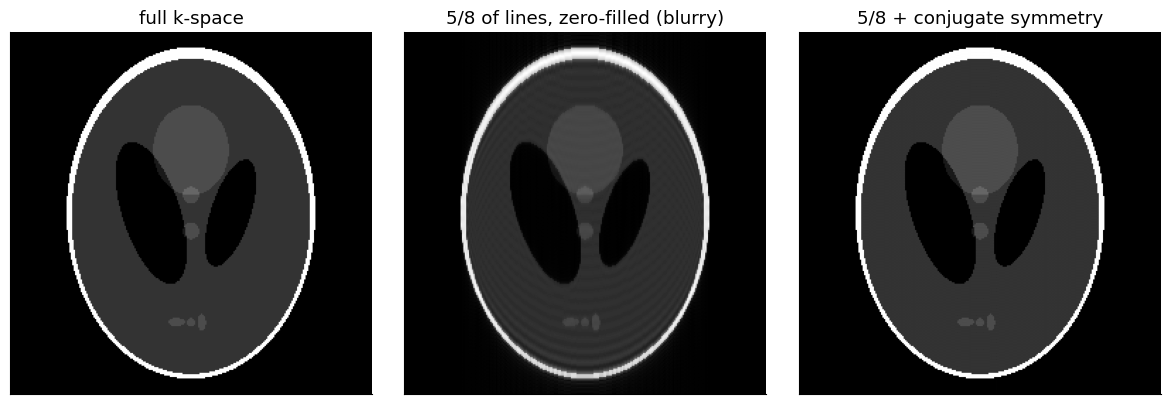

rms error with conjugate fill: 2.19e-03


In [4]:
img = mt.shepp_logan(256)                           # a real-valued object
K = mt.fft2c(img); N = 256
rows = np.arange(N) - N//2                           # k_y index
acq = rows >= -N//8                                  # acquire 5/8 of the lines (all k_y >= -N/8)
K_pf = K * acq[:, None]
# fill the missing lines from conjugate symmetry: M(-k) = conj(M(k)); with centered FFTs index i <-> (N - i) mod N
K_sym = K_pf.copy()
miss = ~acq
idx = (N - np.arange(N)) % N                         # index of -k for every k (both axes)
K_sym[miss, :] = np.conj(K_pf[idx][:, idx])[miss, :]
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
mt.show_image(img, ax=ax[0], title="full k-space")
mt.show_image(mt.ifft2c(K_pf), ax=ax[1], title="5/8 of lines, zero-filled (blurry)")
mt.show_image(mt.ifft2c(K_sym), ax=ax[2], title="5/8 + conjugate symmetry")
plt.tight_layout(); plt.show()
print("rms error with conjugate fill: %.2e" % np.sqrt(np.mean((np.abs(mt.ifft2c(K_sym)) - img)**2)))

*Interpretation:* zero-filling the missing lines loses resolution in that direction; exploiting the symmetry recovers
the image exactly here (because the phantom is real). With real data, phase errors make this approximate (homodyne,
POCS reconstructions, see H3).

### 3.2 Parallel imaging

Skipping every second phase-encode line doubles $\Delta k_y$, halves the FOV and makes the image fold over (P1.3).
But each coil element of an array sees the folded pixels with *different* sensitivities $C_n$. For each pair of
overlapping pixels we have one equation per coil and only two unknowns — solvable if the coils differ enough
(**SENSE**). **GRAPPA** does the equivalent in k-space by learning how to fill missing lines from neighbours.

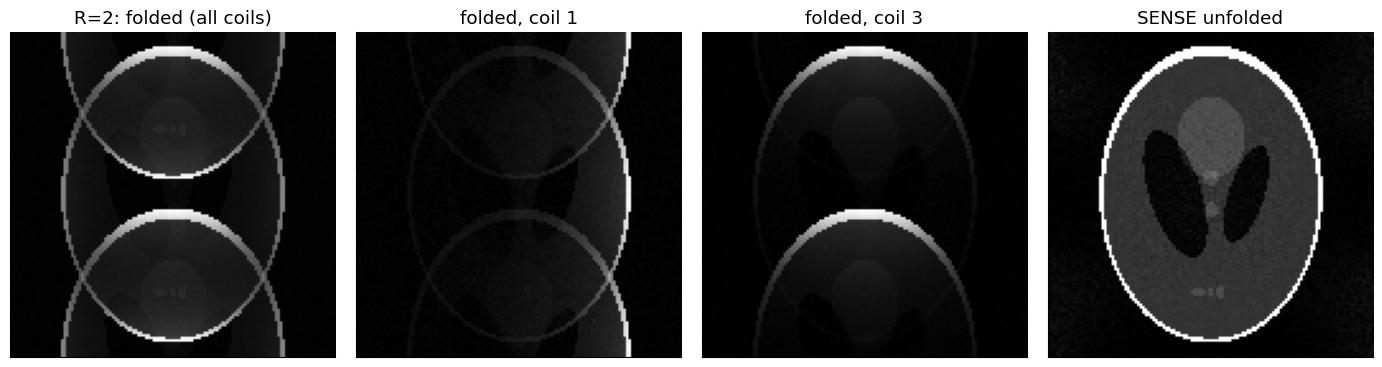

In [5]:
n = 128
obj = mt.shepp_logan(n)
xs = np.linspace(-0.12, 0.12, n); X, Y = np.meshgrid(xs, xs[::-1])
pts = np.stack([X, Y, 0*X], -1)
coils = [((0.14, 0, 0), "x"), ((-0.14, 0, 0), "x"), ((0, 0.14, 0), "y"), ((0, -0.14, 0), "y")]
C = []
for center, normal in coils:                          # coil sensitivities from Biot-Savart (as in P1.2)
    B = mt.loop_coil_field(pts, 0.06, 1.0, center=center, normal=normal)
    C.append(B[..., 0] + 1j*B[..., 1])
C = np.array(C); C /= np.abs(C).max()

R = 2
rng = np.random.default_rng(0)
coil_imgs = C * obj                                   # what each coil "sees"
K_c = mt.fft2c(coil_imgs)
K_c = mt.add_complex_noise(K_c, 0.002, rng)
K_sub = np.zeros_like(K_c); K_sub[:, ::R, :] = K_c[:, ::R, :]   # keep every 2nd phase-encode line (axis 0 = y)
alias = R * mt.ifft2c(K_sub)                          # folded coil images: m(y) + m(y + FOV/2)

# SENSE unfolding: for each pixel pair (y, y+n/2) solve a 4x2 least-squares problem
h = n//2
A = np.stack([C[:, :h, :], C[:, h:, :]], axis=-1)     # (coils, h, n, 2)
A = np.moveaxis(A, 0, 2)                              # (h, n, coils, 2)
b = np.moveaxis(alias[:, :h, :], 0, -1)[..., None]    # (h, n, coils, 1); aliased value is the same in both halves
sol = np.linalg.pinv(A) @ b                           # (h, n, 2, 1)
sense = np.concatenate([sol[..., 0, 0], sol[..., 1, 0]], axis=0)

fig, ax = plt.subplots(1, 4, figsize=(14, 3.6))
mt.show_image(np.sqrt((np.abs(alias)**2).sum(0)), ax=ax[0], title="R=2: folded (all coils)")
mt.show_image(alias[0], ax=ax[1], title="folded, coil 1")
mt.show_image(alias[2], ax=ax[2], title="folded, coil 3")
mt.show_image(sense, ax=ax[3], title="SENSE unfolded", vmin=0, vmax=1)
plt.tight_layout(); plt.show()

*Interpretation:* with half the data the combined image is folded; because the coils weight the two overlapping
copies differently, the least-squares unfolding recovers the full-FOV image. Where the coils are similar the
unfolding amplifies noise: the **g-factor**, $SNR_{acc} = SNR/(g\sqrt R)$. **Simultaneous multi-slice** applies the
same idea to several slices excited at once.

![Simultaneous multi-slice](../images/parallel_imaging-simultaneous_multislice.png)

> **TODO (polish):** compute and display a g-factor map for this coil geometry.

### 3.3 Compressed sensing

Most images are **compressible**: in a suitable transform (wavelets, finite differences — or for angiograms the image
itself) only a few coefficients are large. Compressed sensing samples k-space **pseudo-randomly**, so that the
undersampling artifacts look like noise instead of coherent copies, and then solves an iterative reconstruction
that finds the sparsest image consistent with the data. Below: a sparse "angiogram"-like image, ~2.7× random undersampling (37 % of the lines; regular 4× for comparison),
and a simple iterative soft-thresholding reconstruction (ISTA).

sampled fraction: random 0.37, regular 0.25


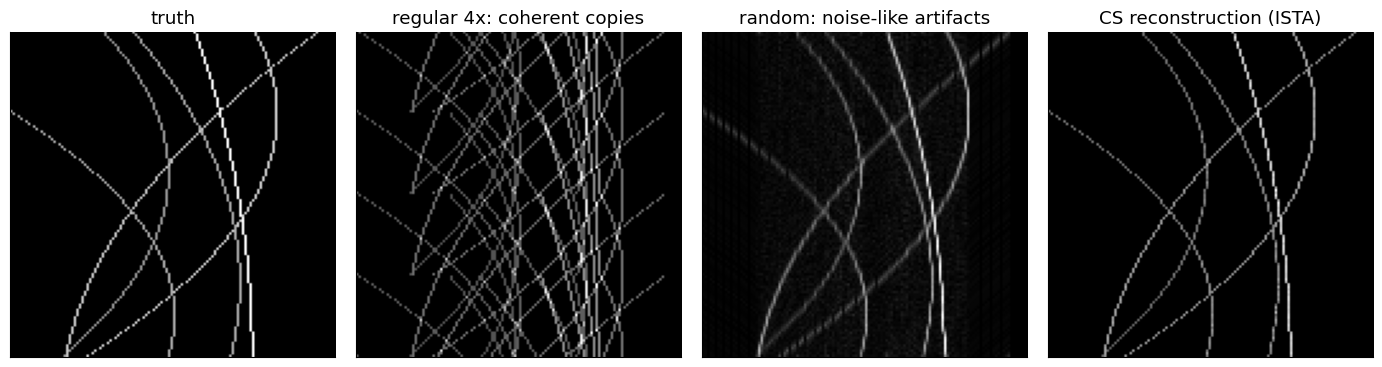

In [6]:
n = 128
rng = np.random.default_rng(3)
vessels = np.zeros((n, n))
yy, xx = np.mgrid[0:n, 0:n]
for k in range(6):                                    # a few thin curved "vessels" and dots
    a, b, c = rng.uniform(-0.01, 0.01), rng.uniform(-1, 1), rng.uniform(10, n - 10)
    xline = (a*(yy - n/2)**2 + b*(yy - n/2) + c).astype(int)
    ok = (xline >= 0) & (xline < n) & (xx == np.clip(xline, 0, n - 1))
    vessels[ok] = rng.uniform(0.5, 1)
K = mt.fft2c(vessels)
ky = np.arange(n) - n//2
p = np.clip(0.9*np.exp(-(ky/(n/6))**2) + 0.12, 0, 1)  # variable density: dense center, sparse edges
mask_rand = (rng.random(n) < p)[:, None] * np.ones((1, n), bool)
mask_reg = np.zeros((n, n), bool); mask_reg[::4, :] = True
print(f"sampled fraction: random {mask_rand.mean():.2f}, regular {mask_reg.mean():.2f}")

def ista(y, mask, lam=0.05, n_iter=100):
    """Minimise ||mask*F x - y||^2 + lam*||x||_1 by iterative soft-thresholding (image-domain sparsity)."""
    x = mt.ifft2c(y)
    for _ in range(n_iter):
        x = x + mt.ifft2c(y - mask*mt.fft2c(x))       # data-consistency (gradient) step
        mag = np.abs(x)
        x = np.where(mag > lam, (1 - lam/np.maximum(mag, 1e-12))*x, 0)   # soft threshold
    return x

y = mask_rand*K
fig, ax = plt.subplots(1, 4, figsize=(14, 3.6))
mt.show_image(vessels, ax=ax[0], title="truth")
mt.show_image(mt.ifft2c(mask_reg*K)*4, ax=ax[1], title="regular 4x: coherent copies")
mt.show_image(mt.ifft2c(y)/mask_rand.mean(), ax=ax[2], title="random: noise-like artifacts")
mt.show_image(ista(y, mask_rand), ax=ax[3], title="CS reconstruction (ISTA)")
plt.tight_layout(); plt.show()

*Interpretation:* regular undersampling gives clean ghost copies that no sparsity prior can remove; random
undersampling gives incoherent "noise" that the soft-thresholding removes while keeping the few strong vessels.
Real CS uses wavelets or total variation for anatomical images and is combined with parallel imaging.

![Compressed sensing concept](../images/compressed_sensing_concept.gif)

### 3.4 Deep-learning reconstruction

Neural networks trained on large sets of fully sampled data (e.g. the public fastMRI dataset) learn what MRI images
look like and reconstruct from undersampled data. The best methods are **unrolled networks**: they alternate a learned
"denoising" step with the physics-based data-consistency step of the iteration above (e.g. the end-to-end variational
network below). Vendors now ship DL reconstructions for denoising and 2–4× faster scans. Caveat: a network can produce
plausible-looking structures that are not in the data ("hallucinations"), especially for pathology unlike the training data.

![End-to-end variational network](../images/end-to-end_varnet.jpg)

➡️ **Go deeper:** [H3 Accelerated Imaging Methods](../pass2_deep_dive/H3_Accelerated_Imaging_Methods.ipynb) · [J5 Advanced Image Reconstruction](../pass2_deep_dive/J5_Advanced_Image_Reconstruction.ipynb) · [B5 RF System and Receive Chain](../pass2_deep_dive/B5_RF_System_and_Receive_Chain.ipynb) (arrays) · [RM4 Fourier properties](../refreshers/RM4_Fourier_Properties.ipynb) (conjugate symmetry)

## 4. Artifacts

Most artifacts are easiest to understand in k-space: something modified the data before the inverse FFT.

| Artifact | Cause | Appearance | Remedies | Direction |
|---|---|---|---|---|
| Aliasing (wrap-around) | FOV smaller than object; failed parallel imaging | parts fold to the opposite side | larger FOV, oversampling, swap PE/FE, sat bands | phase encode |
| Gibbs ringing | k-space truncated at sharp edges | ripples parallel to edges | finer resolution, filtering (window) | both |
| Motion / flow ghosts | object changes between PE lines | copies ("ghosts") of moving tissue | breath-hold, gating, faster scans, radial | phase encode |
| Chemical shift (fat) | fat precesses 3.5 ppm slower | fat displaced, bright/dark bands at fat-water edges | higher bandwidth, fat suppression | frequency (2DFT), phase (EPI) |
| Susceptibility | $\Delta\chi$ distorts $B_0$ near air, metal, implants | distortion, signal voids ($T_2^*$) | spin echo, short TE, high bandwidth, shimming | frequency (2DFT), phase (EPI) |
| Spike noise | intermittent hardware spark | stripes over the whole image | fix hardware, filter spikes | – |
| Zipper (RF interference) | external RF leaking into the room | line of noise at fixed frequency | close door, find source | along PE at one readout position |
| Dielectric / RF shading | $B_1^+$ inhomogeneity at high field | dark/bright regions | dielectric pads, parallel transmit, bias correction | – |
| Gradient non-linearity | gradients not linear far from center | warping at FOV edges | distortion correction | – |

Simulations on measured k-space data (sagittal T1-weighted spin echo; phase encoding along the vertical axis):

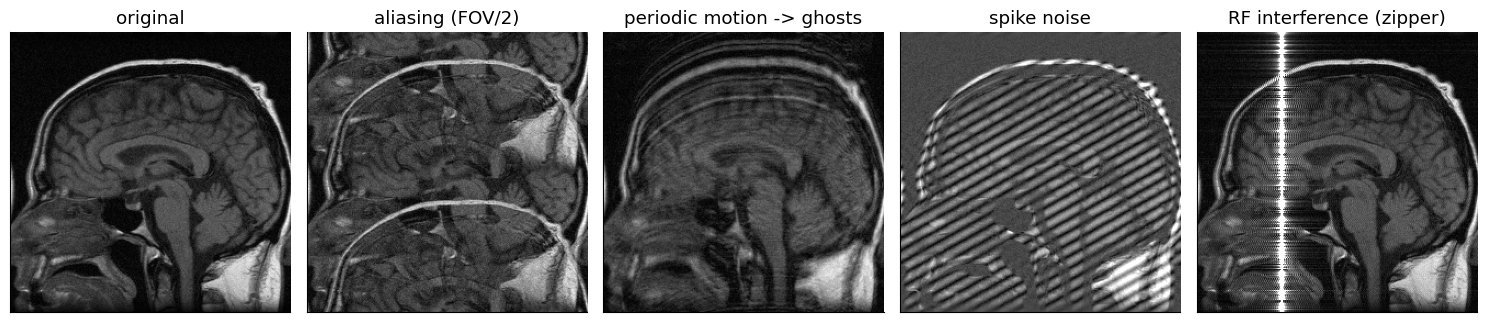

In [7]:
from scipy.io import loadmat
kdata = loadmat("../data/se_t1_sag_data.mat")["data"]
Ny, Nx = kdata.shape
im0 = np.abs(mt.ifft2c(kdata)); vmax = im0.max()

# aliasing: every 2nd phase-encode line (FOV halved)
K_alias = np.zeros_like(kdata); K_alias[::2] = kdata[::2]
# motion: periodic translation along y during the acquisition (e.g. breathing), period 16 TRs, amplitude 3 pixels
n_pe = np.arange(Ny); ky = (n_pe - Ny//2)[:, None] / Ny
shift = 3*np.sin(2*np.pi*n_pe/16)[:, None]
K_motion = kdata * np.exp(-1j*2*np.pi*ky*shift)
# spike: one corrupted k-space sample
K_spike = kdata.copy(); K_spike[150, 140] += 2*np.abs(kdata).max()
# zipper: a narrow-band interference at a fixed frequency, present in every line with random phase
rng = np.random.default_rng(0)
kx = np.arange(Nx)
K_zip = kdata + 0.02*np.abs(kdata).max()*np.exp(1j*2*np.pi*0.2*kx)[None, :]*np.exp(1j*2*np.pi*rng.random((Ny, 1)))

fig, ax = plt.subplots(1, 5, figsize=(15, 3.4))
for a, (Kx, t) in zip(ax, [(kdata, "original"), (K_alias, "aliasing (FOV/2)"), (K_motion, "periodic motion -> ghosts"),
                           (K_spike, "spike noise"), (K_zip, "RF interference (zipper)")]):
    mt.show_image(mt.ifft2c(Kx)*(2 if t.startswith("alias") else 1), ax=a, title=t, vmin=0, vmax=vmax)
plt.tight_layout(); plt.show()

*Interpretation:* aliasing folds the back of the head onto the front (vertical = phase-encode direction). The periodic
motion produces faint copies of the head displaced along the phase-encode direction, spaced by $FOV\cdot TR/T_{motion}$
(here FOV/16). A single bad k-space point puts a stripe pattern over the entire image. The interference at one
frequency becomes a vertical line at one horizontal position.

**Chemical shift.** Fat precesses $\Delta f_{cs}$ ≈ −3.5 ppm (−447 Hz at 3 T) slower than water; the readout
interprets frequency as position, so fat is displaced by $\Delta f_{cs}/(BW_{read}/N_{read})$ pixels. We shift the fat
ring of the phantom by the amounts computed in Section 2:

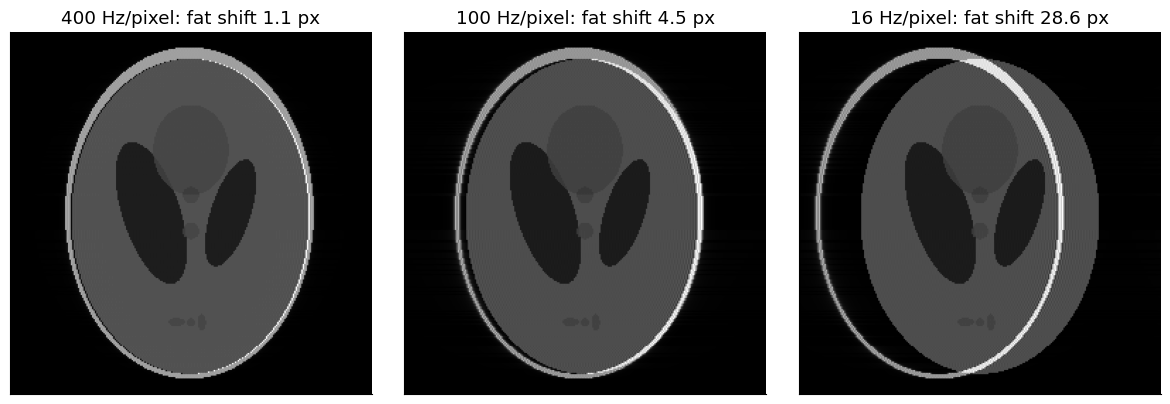

In [8]:
ph = mt.tissue_phantom(256)
S = mt.spin_echo_signal(0.015, 0.5, ph["T1"], ph["T2"], ph["M0"])
fat = np.where(ph["labels"] == 1, S, 0); water = S - fat
kx = (np.arange(256) - 128)[None, :] / 256
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for a, bwp in zip(ax, [400, 100, 1/(128*0.5e-3)]):
    shift_px = df_fat / bwp                              # negative frequency -> shift to the left along x (readout)
    fat_shifted = mt.ifftc(mt.fftc(fat, axis=1) * np.exp(-1j*2*np.pi*kx*shift_px), axis=1)
    mt.show_image(np.abs(water + fat_shifted), ax=a, title=f"{bwp:.0f} Hz/pixel: fat shift {abs(shift_px):.1f} px")
plt.tight_layout(); plt.show()

*Interpretation:* at high bandwidth the shift is negligible; at low bandwidth (or in the EPI phase-encode direction)
the fat ring visibly separates from the "brain", leaving a dark gap on one side and a bright overlap on the other.

**Susceptibility.** Air (in sinuses, ear canals, bowel) and metal have different magnetic susceptibility $\chi$ from
tissue ($\Delta\chi$ ≈ 9 ppm for air–tissue), so $B_0$ is distorted nearby by several ppm. Result: geometric
distortion (as for chemical shift, but spatially varying) and signal loss from intra-voxel dephasing ($T_2^*$),
strongest in EPI and gradient echo, weakest in spin echo with high bandwidth.

| ![EPI distortion](../images/artifacts/epi_distortion_artifact_changes.jpg) | ![T2* artifact](../images/artifacts/epi_T2star_artifact.png) |
| :-: | :-: |
| EPI distortion near the sinuses | $T_2^*$ signal loss |

| ![Aliasing](../images/artifacts/abdomen_aliasing.png) | ![Motion](../images/artifacts/abdomen_motion.png) | ![EPI fat](../images/artifacts/epi_fat_artifact.jpg) |
| :-: | :-: | :-: |
| aliasing (abdomen) | respiratory motion ghosts | fat displacement in EPI |

*Clinical examples from Larson's book.*

> **TODO (polish):** add a simulated susceptibility (dipole field) distortion demo and a Gibbs-ringing/window demo here.

➡️ **Go deeper:** [I2 Artifacts](../pass2_deep_dive/I2_Artifacts.ipynb) · [I1 Point Spread Function Analysis](../pass2_deep_dive/I1_Point_Spread_Function_Analysis.ipynb) · [G1 FOV and Resolution](../pass2_deep_dive/G1_FOV_and_Resolution.ipynb) · [A3 In Vivo Spin Physics](../pass2_deep_dive/A3_In_Vivo_Spin_Physics.ipynb) · [RM5 Fourier pairs & sampling](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb)

## 5. Safety

MRI uses no ionizing radiation and is very safe *when the rules are followed*. Each hardware component of P1.2 has its
own hazard:

| Hazard | Source | Limit / rule | Mitigation |
|---|---|---|---|
| **Projectiles** | spatial gradient of the fringe field pulls ferromagnetic objects ($F \propto$ field × field gradient) | no ferromagnetic objects in Zone IV | screening, access zones I–IV, MR-safe equipment |
| **Implants** | force/torque on metal, RF heating of leads, device malfunction | labels: MR Safe / MR Conditional / MR Unsafe (ASTM F2503) | follow the implant's conditions (field, SAR, slew rate) |
| **RF heating** | SAR; current loops; resonant wires | 2 W/kg whole body, 3.2 W/kg head (normal mode, IEC 60601-2-33); core temperature rise ≤ 0.5 °C | weight-based SAR monitoring, pads, no skin-to-skin loops, cables straight |
| **Nerve stimulation (PNS)** | $dB/dt$ from gradient switching | limited to below the PNS threshold (cardiac threshold is far higher) | scanner-enforced slew limits |
| **Acoustic noise** | Lorentz forces on gradient coils | hearing protection required; ≤ 99 dB(A) at the ear with protection | earplugs + headphones, quiet sequences |
| **Quench / cryogens** | boiling helium | quench pipe to outside, O₂ monitors | emergency procedures |
| **Contrast agents** | gadolinium chelates | caution in severe renal failure (NSF); Gd deposition in brain (clinical significance unknown) | macrocyclic agents, lowest dose, only when needed |
| Others | claustrophobia, pregnancy, static-field effects (vertigo, metallic taste at 7 T) | Gd avoided in pregnancy unless essential | communication, wide-bore scanners |

The projectile force is largest not inside the bore (where the field is uniform) but near the bore entrance, where the
field changes fastest. Using the same simplified magnet as in P1.2:

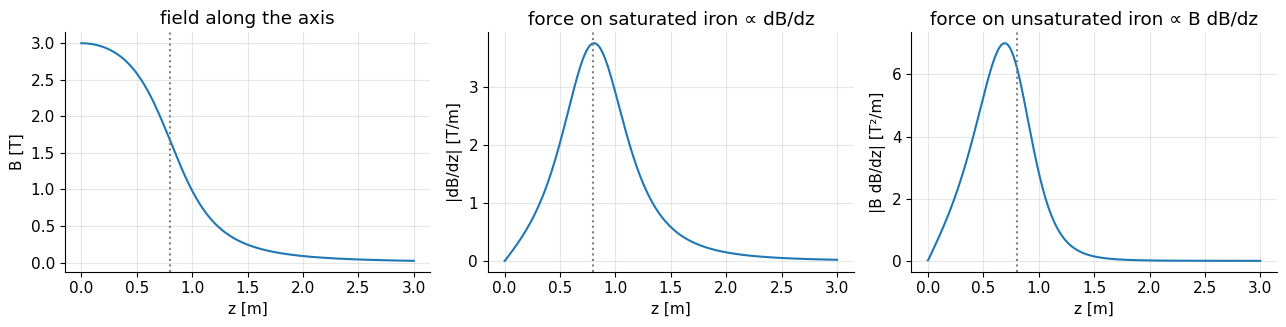

maximum |B dB/dz| = 7.0 T^2/m at z = 0.69 m (bore end at 0.8 m)


In [9]:
z = np.linspace(0, 3, 600)                            # distance from the magnet center along the axis [m]
R_mag = 0.45
z_loops = np.linspace(-0.8, 0.8, 161)                 # simple 1.6 m solenoid, scaled to 3 T at the center
B = sum(mt.loop_field_on_axis(z - zl, R_mag, 1.0) for zl in z_loops)
B *= 3.0 / sum(mt.loop_field_on_axis(0.0 - zl, R_mag, 1.0) for zl in z_loops)
dBdz = np.gradient(B, z)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
ax[0].plot(z, B); ax[0].set(xlabel="z [m]", ylabel="B [T]", title="field along the axis")
ax[1].plot(z, np.abs(dBdz)); ax[1].set(xlabel="z [m]", ylabel="|dB/dz| [T/m]", title="force on saturated iron ∝ dB/dz")
ax[2].plot(z, np.abs(B*dBdz)); ax[2].set(xlabel="z [m]", ylabel="|B dB/dz| [T²/m]", title="force on unsaturated iron ∝ B dB/dz")
for a in ax: a.axvline(0.8, color="gray", ls=":")
plt.tight_layout(); plt.show()
print(f"maximum |B dB/dz| = {np.abs(B*dBdz).max():.1f} T^2/m at z = {z[np.argmax(np.abs(B*dBdz))]:.2f} m (bore end at 0.8 m)")

*Interpretation:* the pull peaks near the bore opening (dotted line) and grows within centimetres — a pair of
scissors can go from "slightly heavy" to "flying" in one step. (Actively shielded magnets have even steeper fringe
gradients close to the bore.)

> **TODO (polish):** fact-check the precise IEC 60601-2-33 numbers (first-level modes, local SAR, PNS formulas) in B6.

➡️ **Go deeper:** [B6 MRI Safety](../pass2_deep_dive/B6_MRI_Safety.ipynb) · [B3 Main Magnet Engineering](../pass2_deep_dive/B3_Main_Magnet_Engineering.ipynb) · [B4 Gradient System Engineering](../pass2_deep_dive/B4_Gradient_System_Engineering.ipynb) · [B5 RF System and Receive Chain](../pass2_deep_dive/B5_RF_System_and_Receive_Chain.ipynb) · [D2 In Vivo Contrast Mechanisms](../pass2_deep_dive/D2_In_Vivo_Contrast_Mechanisms.ipynb) (contrast agents)

## 6. The map of Pass 2

You now have the whole picture. Pass 2 revisits every piece in depth, with full mathematics and engineering.
Suggested order: A → B → C → D → E → F → G → H → I; part J is advanced.

| Chapter | What you'll learn | Refreshers that help |
|---|---|---|
| [A1 Spin Physics](../pass2_deep_dive/A1_Spin_Physics.ipynb) | nuclear spin, polarization formula, resonance | [RP4](../refreshers/RP4_Spin_and_Thermal_Statistics.ipynb), [RP3](../refreshers/RP3_Precession_and_Torque.ipynb) |
| [A2 Bloch Equation](../pass2_deep_dive/A2_Bloch_Equation.ipynb) | equation of motion of $\vec M$, lab vs rotating frame, relaxation | [RM1](../refreshers/RM1_ODEs_for_MRI.ipynb), [RM2](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb), [RP3](../refreshers/RP3_Precession_and_Torque.ipynb) |
| [A3 In Vivo Spin Physics](../pass2_deep_dive/A3_In_Vivo_Spin_Physics.ipynb) | susceptibility, chemical shift, fat | [RP1](../refreshers/RP1_Magnetism_from_Currents.ipynb) |
| [B1 MRI System](../pass2_deep_dive/B1_MRI_System.ipynb) | components, experiment, calibrations | – |
| [B2 Magnetic Fields in MRI](../pass2_deep_dive/B2_Magnetic_Fields_in_MRI.ipynb) | coil fields, transmit/receive, reciprocity, coil profiles | [RP1](../refreshers/RP1_Magnetism_from_Currents.ipynb), [RP2](../refreshers/RP2_Induction_and_RF.ipynb) |
| [B3 Main Magnet Engineering](../pass2_deep_dive/B3_Main_Magnet_Engineering.ipynb) | superconductors, cryogenics, quench, homogeneity, shimming, siting | [RP1](../refreshers/RP1_Magnetism_from_Currents.ipynb) |
| [B4 Gradient System Engineering](../pass2_deep_dive/B4_Gradient_System_Engineering.ipynb) | coil design, inductance, amplifiers, eddy currents, PNS, acoustics | [RP1](../refreshers/RP1_Magnetism_from_Currents.ipynb), [RP2](../refreshers/RP2_Induction_and_RF.ipynb) |
| [B5 RF System and Receive Chain](../pass2_deep_dive/B5_RF_System_and_Receive_Chain.ipynb) | RF amplifiers, tuning/matching, birdcage, arrays, preamps, ADC, noise, $B_1^+$ | [RP2](../refreshers/RP2_Induction_and_RF.ipynb), [RM2](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb) |
| [B6 MRI Safety](../pass2_deep_dive/B6_MRI_Safety.ipynb) | projectiles, SAR & heating, PNS, acoustic, implants, quench, contrast agents | [RP2](../refreshers/RP2_Induction_and_RF.ipynb) |
| [C1 Pulse Sequence](../pass2_deep_dive/C1_Pulse_Sequence.ipynb) | reading and designing pulse-sequence diagrams | – |
| [C2 MRI Signal Equation](../pass2_deep_dive/C2_MRI_Signal_Equation.ipynb) | the signal as an integral over the object; demodulation | [RM2](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb), [RM3](../refreshers/RM3_Continuous_FT_and_DFT.ipynb) |
| [D1 Basic Contrast Mechanisms](../pass2_deep_dive/D1_Basic_Contrast_Mechanisms.ipynb) | $T_1$/$T_2$/PD weighting, steady state, inversion recovery | [RM1](../refreshers/RM1_ODEs_for_MRI.ipynb) |
| [D2 In Vivo Contrast Mechanisms](../pass2_deep_dive/D2_In_Vivo_Contrast_Mechanisms.ipynb) | $T_2^*$, phase, fat/water, contrast agents | [RM2](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb) |
| [D3 Gradient and Spin Echoes](../pass2_deep_dive/D3_Gradient_and_Spin_Echoes.ipynb) | how echoes form and refocus | [RM2](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb) |
| [D4 Image Contrast Examples](../pass2_deep_dive/D4_Image_Contrast_Examples.ipynb) | real contrast examples and protocols | – |
| [E1 RF Pulses](../pass2_deep_dive/E1_RF_Pulses.ipynb) | flip angle, pulse shapes, bandwidth, SAR | [RM5](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb) |
| [E2 Slice Selection](../pass2_deep_dive/E2_Slice_Selection.ipynb) | slice thickness/position, refocusing | [RM4](../refreshers/RM4_Fourier_Properties.ipynb) |
| [E3 RF Pulse Design](../pass2_deep_dive/E3_RF_Pulse_Design.ipynb) | windowed sinc, SLR, small-tip approximation | [RM5](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb) |
| [F1 Spatial Encoding](../pass2_deep_dive/F1_Spatial_Encoding.ipynb) | frequency and phase encoding in detail | [RM3](../refreshers/RM3_Continuous_FT_and_DFT.ipynb) |
| [F2 K-space](../pass2_deep_dive/F2_K-space.ipynb) | k-space formalism, trajectories | [RM6](../refreshers/RM6_2D_Fourier_and_Images.ipynb) |
| [F3 Image Reconstruction](../pass2_deep_dive/F3_Image_Reconstruction.ipynb) | FFT reconstruction, coil combination | [RM3](../refreshers/RM3_Continuous_FT_and_DFT.ipynb), [RM6](../refreshers/RM6_2D_Fourier_and_Images.ipynb) |
| [G1 FOV and Resolution](../pass2_deep_dive/G1_FOV_and_Resolution.ipynb) | sampling ↔ FOV, extent ↔ resolution | [RM5](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb) |
| [G2 Signal to Noise Ratio](../pass2_deep_dive/G2_Signal_to_Noise_Ratio.ipynb) | the SNR equation, efficiency | – |
| [G3 Cartesian Image Characteristics](../pass2_deep_dive/G3_Cartesian_Image_Characteristics.ipynb) | converting protocol parameters to image properties | – |
| [H1 Volumetric Imaging](../pass2_deep_dive/H1_Volumetric_Imaging.ipynb) | multislice vs 3D | [RM6](../refreshers/RM6_2D_Fourier_and_Images.ipynb) |
| [H2 Fast Imaging Pulse Sequences](../pass2_deep_dive/H2_Fast_Imaging_Pulse_Sequences.ipynb) | FSE, EPI, fast GRE, bSSFP, MPRAGE | – |
| [H3 Accelerated Imaging Methods](../pass2_deep_dive/H3_Accelerated_Imaging_Methods.ipynb) | partial Fourier, parallel imaging, CS, DL | [RM4](../refreshers/RM4_Fourier_Properties.ipynb) |
| [I1 Point Spread Function Analysis](../pass2_deep_dive/I1_Point_Spread_Function_Analysis.ipynb) | PSF, blurring from relaxation and sampling | [RM4](../refreshers/RM4_Fourier_Properties.ipynb), [RM5](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb) |
| [I2 Artifacts](../pass2_deep_dive/I2_Artifacts.ipynb) | all artifacts, simulated and real | [RM4](../refreshers/RM4_Fourier_Properties.ipynb) |
| [J1 Excitation K-space](../pass2_deep_dive/J1_Excitation_K-space.ipynb) *(advanced)* | RF pulses as k-space trajectories | [RM6](../refreshers/RM6_2D_Fourier_and_Images.ipynb) |
| [J2 Spectral-Spatial RF Pulses](../pass2_deep_dive/J2_Spectral-Spatial_RF_Pulses.ipynb) *(advanced)* | water-only excitation | [RM5](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb) |
| [J3 Fun with RF Pulses](../pass2_deep_dive/J3_Fun_with_RF_Pulses.ipynb) *(advanced)* | adiabatic and other special pulses | [RM2](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb) |
| [J4 Advanced SNR](../pass2_deep_dive/J4_Advanced_SNR.ipynb) *(advanced)* | noise statistics, g-factor, coil combination | – |
| [J5 Advanced Image Reconstruction](../pass2_deep_dive/J5_Advanced_Image_Reconstruction.ipynb) *(advanced)* | non-Cartesian, iterative, model-based reconstruction | [RM4](../refreshers/RM4_Fourier_Properties.ipynb) |

Reference material: [Notation and Symbols](../reference/Notation_and_Symbols.ipynb) · [Glossary and Acronyms](../reference/Glossary_and_Acronyms.ipynb) · [Key MRI Concepts](../reference/Key_MRI_Concepts.ipynb) · [MRI Math Concepts](../reference/MRI_Math_Concepts.ipynb) · [Questions](../reference/Questions.ipynb) · [Software Resources](../reference/Software_Resources.ipynb)

## Key takeaways

* Basic scan time $= TR\cdot N_{PE}\cdot NEX$; echo trains ($ETL$) and acceleration ($R$) divide it: $N_{TR} = N_{PE}NEX/(ETL\cdot R)$.
* **FSE** (many spin echoes per TR), **EPI** (whole k-space per shot) and **fast GRE** (TR of ms) are the fast workhorses; EPI is fast but distortion-prone.
* Acceleration skips data and uses prior knowledge: symmetry (**partial Fourier**), coil sensitivities (**parallel imaging**, $SNR/(g\sqrt R)$), sparsity (**compressed sensing**), learned image statistics (**deep learning**).
* Artifacts are best understood in k-space: **aliasing** and **motion ghosts** along phase encode, **chemical shift** and **susceptibility** distortions ∝ off-resonance ÷ bandwidth per pixel, spikes and zippers from hardware.
* Safety: **projectiles** (strongest pull at the bore entrance), **implants**, **SAR** (2 W/kg body), **PNS**, **acoustic noise**, **quench**, **gadolinium**.

## Check your understanding

**1.** A T2-weighted FSE has TR = 3 s, 320 phase-encode lines, ETL = 20 and NEX = 1. How long does it take? And with $R = 2$?

<details><summary>Answer</summary>

$3\,\text{s}\times 320/20 = 48$ s; with $R=2$, 24 s (at the cost of SNR × $1/(g\sqrt2)$).

</details>

**2.** Why do aliasing and motion ghosts appear only along the phase-encode direction in a 2DFT scan?

<details><summary>Answer</summary>

Along the readout, samples are taken microseconds apart (no motion in between) and an analog/digital low-pass filter
removes frequencies outside the FOV. Along phase encode, successive lines are acquired one TR apart (motion changes
the data between lines), and nothing filters signal outside the phase-encode FOV.

</details>

**3.** Fat is displaced by 3 pixels at 150 Hz/pixel on a 3 T scanner. What would the displacement be at 1.5 T with the same bandwidth?

<details><summary>Answer</summary>

The shift in Hz is proportional to $B_0$: 447 Hz at 3 T vs 224 Hz at 1.5 T, so ~1.5 pixels.

</details>

**4.** Why does compressed sensing use *random* undersampling rather than skipping every n-th line?

<details><summary>Answer</summary>

Regular undersampling produces coherent copies of the object, which look like real structure and cannot be removed
by a sparsity prior. Random undersampling spreads the artifacts as noise-like interference, which a sparsity-promoting
reconstruction can separate from the few strong true coefficients.

</details>

**5.** Where near an MRI scanner is the attractive force on a ferromagnetic object largest, and why?

<details><summary>Answer</summary>

Near the bore entrance, where the field changes most rapidly with position; the force depends on the field *gradient*
(∝ $dB/dz$ or $B\,dB/dz$), which is almost zero in the uniform center of the bore.

</details>

---
*Adapted and extended from P. Larson, "Principles of MRI" (MIT License), chapters "Fast Imaging Pulse Sequences", "Accelerated Imaging Methods", "Artifacts" and "Key MRI Concepts".
Changes: rewritten as an overview; added scan-time calculator, partial Fourier, SENSE and compressed-sensing demos, artifact simulations on measured data, a chemical-shift demo, a safety section with a fringe-field force demo, and a full map of Pass 2.*